# 1. Git
Version code, configuration and the data generator so an experiment can be traced to the files that produced it.

In [1]:
from pathlib import Path
import os
import sys
import time
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
started = time.perf_counter()
from IPython.display import display, Markdown, HTML
from fraud.git_demo import demonstrate
print(demonstrate())

$ git status --short
M notebooks/01_fraud_detection.ipynb
 M notebooks/02_mlops.ipynb
 M src/fraud/registry.py
?? README.md
?? docs/talk_notes.md
?? scripts/write_docs.py
$ git add .

$ git commit --allow-empty -m Checkpoint classroom project
[main d19fafa] Checkpoint classroom project
 6 files changed, 1288 insertions(+), 134 deletions(-)
 create mode 100644 README.md
 create mode 100644 docs/talk_notes.md
 create mode 100644 scripts/write_docs.py
$ git switch -c lesson/config-10
Switched to a new branch 'lesson/config-10'
$ git add config.yaml

$ git commit -m Clarify classroom configuration note
[lesson/config-10 1697350] Clarify classroom configuration note
 1 file changed, 1 insertion(+), 1 deletion(-)
$ git switch main
Switched to branch 'main'
$ git merge --no-ff lesson/config-10 -m Merge configuration lesson
Merge made by the 'ort' strategy.
 config.yaml | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)
$ git tag lesson-v10

$ git log --graph --oneline -7
*   06ee591 Merge 

In [2]:
import subprocess
commit = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD'], text=True).strip()
display(Markdown(f'The local repository now includes a feature-branch edit, merge and tag at commit {commit}. Only demo_note changes, so the seed, model settings and costs stay fixed.'))

The local repository now includes a feature-branch edit, merge and tag at commit 06ee591. Only demo_note changes, so the seed, model settings and costs stay fixed.

# 2. Experiment tracking with MLflow
Retrain the same three models and log parameters, validation metrics, pipelines, thresholds and provenance to local SQLite and artifact files.

In [3]:
import pandas as pd
from fraud.config import load_config
from fraud.cleaning import clean_data, time_split
from fraud.features import add_features
from fraud.registry import track_models, start_ui
config = load_config()
frame = add_features(clean_data(pd.read_csv('data/transactions.csv')), config)
train, validation, _ = time_split(frame, config)
records, best, runs, comparison = track_models(train, validation, config)
columns = ['tags.mlflow.runName', 'metrics.pr_auc', 'metrics.recall', 'metrics.precision', 'metrics.cost_per_txn', 'params.threshold', 'tags.git_commit', 'tags.config_hash']
display(runs[columns])
display(Markdown(f'This experiment records {len(records)} learned models; {best} has the lowest validation cost at INR {comparison.loc[best, "cost_per_txn"]:.2f} per transaction. Git SHA and the configuration hash link each run to its inputs.'))

2026/11/25 09:49:04 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/25 09:49:04 INFO mlflow.store.db.utils: Updating database tables


2026-11-25 09:49:04 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


2026-11-25 09:49:04 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


2026-11-25 09:49:04 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


2026-11-25 09:49:04 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


,tags.mlflow.runName,metrics.pr_auc,metrics.recall,metrics.precision,metrics.cost_per_txn,params.threshold,tags.git_commit,tags.config_hash
0,LightGBM,0.392146,0.696078,0.178392,14.895130,0.67,06ee591220cf799afa8a14e982ccbe30867868a8,c0b4263e509bffca62961054b2beaaa1f4af90daf08c46...
1,Random Forest,0.328691,0.715686,0.141473,15.558715,0.45,06ee591220cf799afa8a14e982ccbe30867868a8,c0b4263e509bffca62961054b2beaaa1f4af90daf08c46...
2,Logistic Regression,0.254104,0.666667,0.143763,16.885887,0.73,06ee591220cf799afa8a14e982ccbe30867868a8,c0b4263e509bffca62961054b2beaaa1f4af90daf08c46...


This experiment records 3 learned models; LightGBM has the lowest validation cost at INR 14.90 per transaction. Git SHA and the configuration hash link each run to its inputs.

In [4]:
url = start_ui()
display(Markdown(f'MLflow UI is responding at [{url}]({url}); experiment fraud-local contains the recorded runs. The database is mlflow.db and artifacts are under mlartifacts/.'))

MLflow UI is responding at [http://127.0.0.1:5000](http://127.0.0.1:5000); experiment fraud-local contains the recorded runs. The database is mlflow.db and artifacts are under mlartifacts/.

# 3. Model registry
Use champion and challenger aliases to demonstrate a reversible model-version choice without deploying anything.

In [5]:
import inspect
import mlflow
from mlflow import MlflowClient
from fraud.registry import register_candidates, alias_table, move_champion, load_champion
print(f'Installed MLflow: {mlflow.__version__}')
print(inspect.signature(MlflowClient.set_registered_model_alias))
print(inspect.signature(MlflowClient.get_model_version_by_alias))
client, original, challenger = register_candidates(records, best)
display(alias_table(client))
display(Markdown(f'The initial champion is version {original}; challenger is version {challenger}. Each registered version keeps its own threshold as a version tag.'))

2026/11/25 09:49:11 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/25 09:49:11 INFO mlflow.store.db.utils: Updating database tables


2026-11-25 09:49:11 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


2026-11-25 09:49:11 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


Installed MLflow: 3.6.0
(self, name: str, alias: str, version: str) -> None
(self, name: str, alias: str) -> mlflow.entities.model_registry.model_version.ModelVersion


Registered model 'fraud-classroom' already exists. Creating a new version of this model...
Created version '7' of model 'fraud-classroom'.
Registered model 'fraud-classroom' already exists. Creating a new version of this model...
Created version '8' of model 'fraud-classroom'.


,alias,version,run_id
0,champion,7,d0dbc9edca2b4f89b157352c6dcb3d0c
1,challenger,8,5f52f081bb324048a4c48a75ea0db19d


The initial champion is version 7; challenger is version 8. Each registered version keeps its own threshold as a version tag.

In [6]:
display(move_champion(client, challenger))
display(Markdown(f'Promotion moves champion to version {challenger}; challenger still points to that same version. This is an alias-mechanics demonstration, not a quality-approved release.'))
display(move_champion(client, original))
restored = load_champion()
display(Markdown(f'Rollback restores champion to version {restored["registry_version"]}, with estimator {restored["name"]} and threshold {restored["threshold"]:.2f}. The next section evaluates against this current alias.'))

,alias,version,run_id
0,champion,8,5f52f081bb324048a4c48a75ea0db19d
1,challenger,8,5f52f081bb324048a4c48a75ea0db19d


Promotion moves champion to version 8; challenger still points to that same version. This is an alias-mechanics demonstration, not a quality-approved release.

,alias,version,run_id
0,champion,7,d0dbc9edca2b4f89b157352c6dcb3d0c
1,challenger,8,5f52f081bb324048a4c48a75ea0db19d


Rollback restores champion to version 7, with estimator LightGBM and threshold 0.67. The next section evaluates against this current alias.

# 4. Tests and quality gate
Run unit tests and compare each candidate with the current champion on validation data so acceptance has a repeatable rule.

In [7]:
!"{sys.executable}" -m pytest -q
assert get_ipython().user_ns['_exit_code'] == 0, 'pytest failed'

.

..........

...

.

.

.

..                                                      [100%]
19 passed in 5.55s


In [8]:
import html
commands = [[sys.executable, 'scripts/run_gate.py'], [sys.executable, 'scripts/run_gate.py', '--candidate', 'models/baseline.joblib', '--output', 'models/blocked_summary.json']]
results = [subprocess.run(command, capture_output=True, text=True) for command in commands]
assert [result.returncode for result in results] == [0, 1]
columns = [f'<td style="vertical-align:top"><pre>{html.escape(result.stdout)}</pre><b>Exit {result.returncode}</b></td>' for result in results]
display(HTML('<table><tr><th>Selected model</th><th>Always-approve baseline</th></tr><tr>' + ''.join(columns) + '</tr></table>'))
display(Markdown(f'The selected model passes with exit {results[0].returncode}; the baseline is blocked with exit {results[1].returncode}. Tests cover deterministic data, row/batch preprocessing, known metric values, time boundaries and gate failures.'))

Selected model,Always-approve baseline
PASS: All limits passed; candidate cost is no higher than champion. PR-AUC=0.3921; recall=0.6961; cost=INR 14.90/transaction Exit 0,BLOCK: PR-AUC 0.012 < 0.120; recall 0.000 < 0.600; cost INR 36.26 > 20.00; cost INR 36.26 exceeds champion INR 14.90 PR-AUC=0.0121; recall=0.0000; cost=INR 36.26/transaction Exit 1


The selected model passes with exit 0; the baseline is blocked with exit 1. Tests cover deterministic data, row/batch preprocessing, known metric values, time boundaries and gate failures.

# 5. CI with GitHub Actions
Write the workflow and run its checks locally so a commit can trigger the same tests and gate after a future push.

This workflow runs on GitHub’s servers after pushing; the local demonstration uses python scripts/run_ci_local.py and does not contact GitHub. A new CI runner uses an always-approve bootstrap reference because it has no historical registry; the full gate above compares with the actual local champion.

In [9]:
%%writefile .github/workflows/ci.yml
name: Local fraud checks
on: [push, pull_request]
jobs:
  check:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
          cache: pip
      - run: pip install -r requirements.txt

Overwriting .github/workflows/ci.yml


In [10]:
%%writefile -a .github/workflows/ci.yml
      - run: python -m ruff check .
      - run: python -m pytest -q
      - run: python scripts/make_data.py --preset tiny
      - run: python scripts/train_quick.py
      - run: >-
          python scripts/run_gate.py
          --candidate models/ci/candidate.joblib
          --champion models/ci/reference.joblib
          --data data/tiny.csv
          --output models/ci/metrics_summary.json
      - uses: actions/upload-artifact@v4
        if: always()

Appending to .github/workflows/ci.yml


In [11]:
%%writefile -a .github/workflows/ci.yml
        with:
          name: metrics-summary
          path: models/ci/*.json
          if-no-files-found: warn

Appending to .github/workflows/ci.yml


name: Local fraud checks
on: [push, pull_request]
jobs:
  check:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
          cache: pip
      - run: pip install -r requirements.txt
      - run: python -m ruff check .
      - run: python -m pytest -q
      - run: python scripts/make_data.py --preset tiny
      - run: python scripts/train_quick.py
      - run: >-
          python scripts/run_gate.py
          --candidate models/ci/candidate.joblib
          --champion models/ci/reference.joblib
          --data data/tiny.csv
          --output models/ci/metrics_summary.json
      - uses: actions/upload-artifact@v4
        if: always()
        with:
          name: metrics-summary
          path: models/ci/*.json
          if-no-files-found: warn



$ python -m ruff check .
All checks passed!
$ python -m pytest -q
...................                                                      [100%]
19 passed in 6.10s
$ python scripts/make_data.py --preset tiny
tiny.csv: 5,015 rows; fraud 1.476%
$ python scripts/train_quick.py
                     precision  recall  pr_auc  cost_per_txn
model                                                       
Always approve            0.00  0.0000  0.0115       34.4388
Logistic Regression       0.25  0.6667  0.2706       13.7755
Random Forest             0.25  0.6667  0.4629       13.7755
LightGBM                  0.50  0.4444  0.4525       19.6429
Tiny candidate: Random Forest, threshold 0.36
$ python scripts/run_gate.py --candidate models/ci/candidate.joblib --champion models/ci/reference.joblib --data data/tiny.csv --output models/ci/metrics_summary.json
PASS: All limits passed; candidate cost is no higher than champion.
PR-AUC=0.4629; recall=0.6667; cost=INR 13.78/transaction
PASS local CI: 11.45

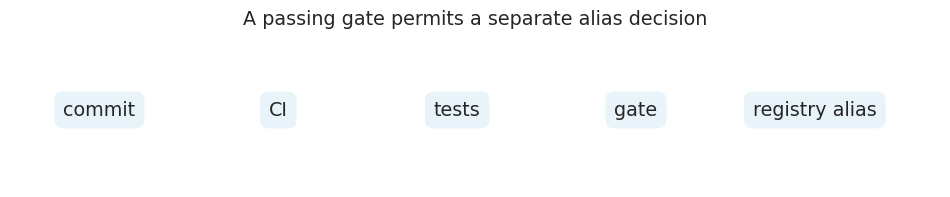

Local CI exits with code 0. CI uploads metrics for review; moving a registry alias remains a separate local decision.

In [12]:
print((ROOT / '.github/workflows/ci.yml').read_text())
ci = subprocess.run([sys.executable, 'scripts/run_ci_local.py'], capture_output=True, text=True)
print(ci.stdout)
if ci.returncode:
    print(ci.stderr)
ci.check_returncode()
from fraud.plots import setup, flow
setup()
flow()
display(Markdown(f'Local CI exits with code {ci.returncode}. CI uploads metrics for review; moving a registry alias remains a separate local decision.'))

In [13]:
import json
elapsed = time.perf_counter() - started
report = {'notebook_body_seconds': elapsed, 'gate_exit_codes': [result.returncode for result in results], 'ci_exit_code': ci.returncode, 'aliases': alias_table(client).to_dict('records')}
(ROOT / 'models/mlops_summary.json').write_text(json.dumps(report, indent=2))
display(Markdown(f'The MLOps notebook body ran in {elapsed:.2f} seconds on this machine, including {len(records)} tracked models, alias promotion and rollback, tests and both gate outcomes. Hosted GitHub Actions and Windows execution have not been tested here.'))

The MLOps notebook body ran in 34.62 seconds on this machine, including 3 tracked models, alias promotion and rollback, tests and both gate outcomes. Hosted GitHub Actions and Windows execution have not been tested here.